In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# from scipy import integrate

In [2]:
def compute_soc(time, current, capacity_Ah=3.4, soc0=1):

    time = np.asarray(time)
    current = np.asarray(current)

    # passo temporale
    dt = np.diff(time, prepend=time[0])

    # integrazione coulomb counting
    soc = np.zeros_like(current, dtype=float)
    soc[0] = soc0

    for k in range(1, len(current)):
        dAh = current[k] * dt[k] / 3600.0
        soc[k] = soc[k-1] - dAh / capacity_Ah


    return soc*100

Processing Battery Testing\test_1.csv
Processing Battery Testing\test_2.csv
Processing Battery Testing\test_3.csv
Processing Battery Testing\test_4.csv
Processing Battery Testing\test_5.csv


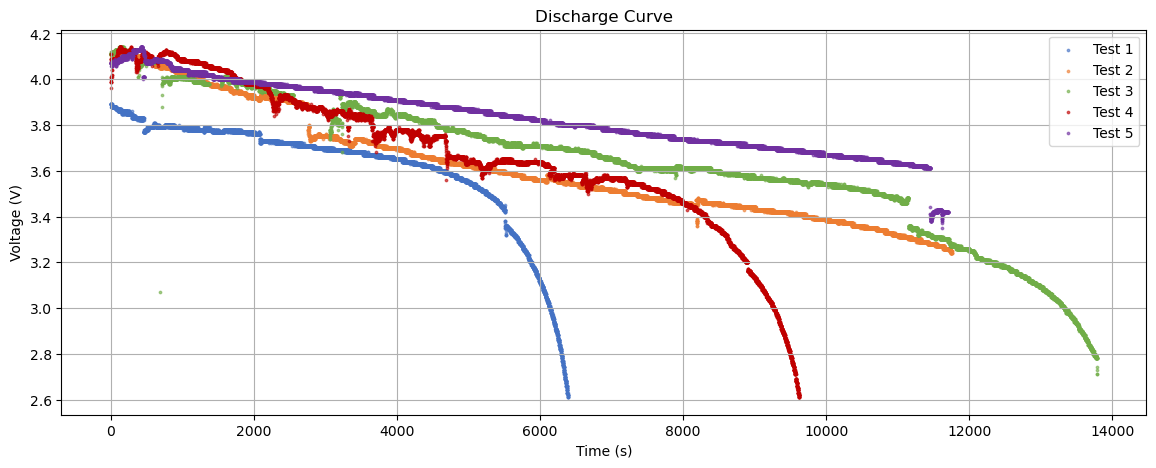

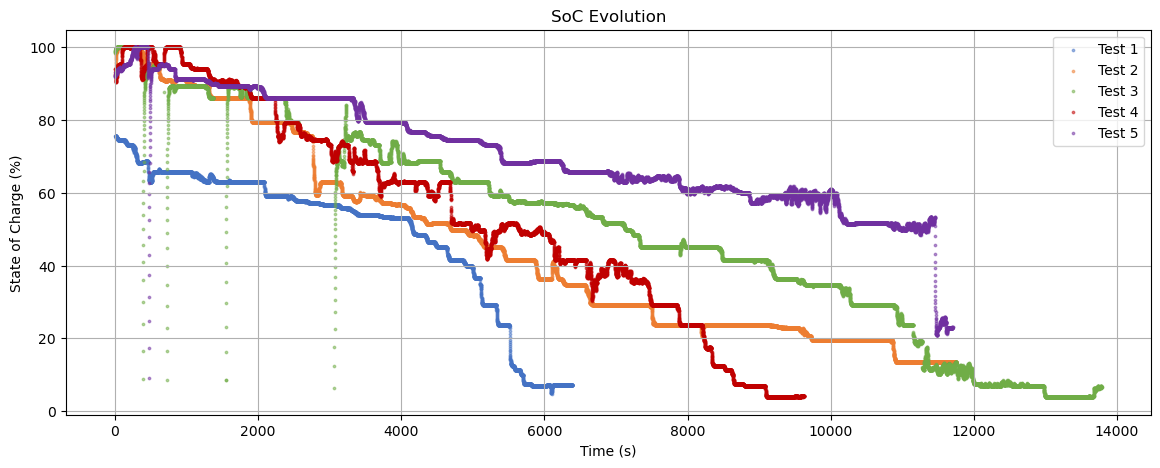

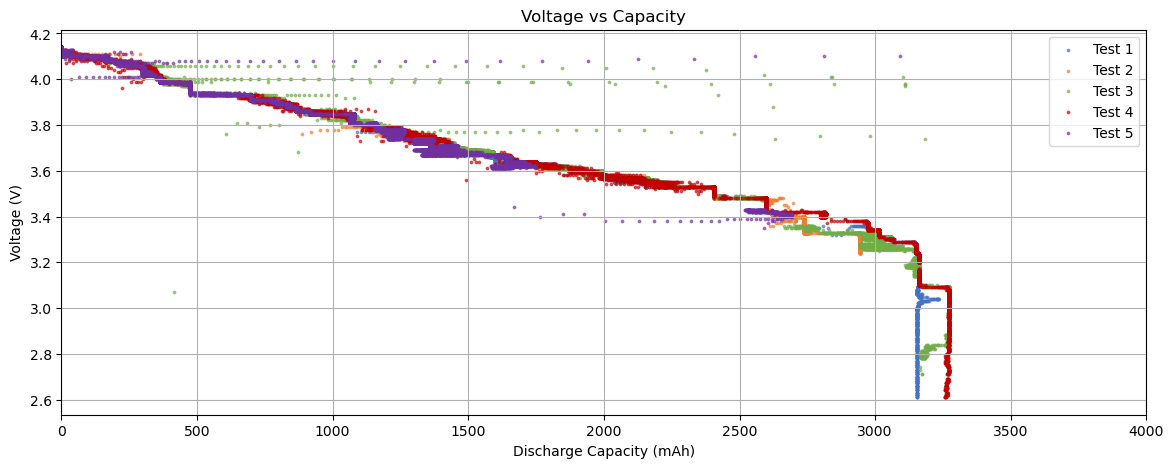

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

base_path = Path(r'.\Battery Testing')
tests = range(1, 6)

# palette colori stabile
colors = [
    '#4472C4',  # blu
    '#ED7D31',  # arancione
    '#70AD47',  # verde
    '#C00000',  # rosso scuro
    '#7030A0',  # viola
]


# ---- FIGURE larghe (una per tipo) ----
fig1 = plt.figure(figsize=(14, 5))
plt.title('Discharge Curve')
plt.grid(True)

fig2 = plt.figure(figsize=(14, 5))
plt.title('SoC Evolution')
plt.grid(True)

fig3 = plt.figure(figsize=(14, 5))
plt.title('Voltage vs Capacity')
plt.grid(True)

# ---- LOOP ----
for idx, i in enumerate(tests):

    file = base_path / f'test_{i}.csv'
    print(f'Processing {file}')

    data = pd.read_csv(file)
    data_cln = data[data.voltage > 2.6]

    time = data_cln.time_s
    current = data_cln.current

    compt_soc = compute_soc(time, current,
                            soc0=data_cln.soc.iloc[0] / 100)

    dod = (100 - data_cln.soc) * 34

    c = colors[idx]

    # ---- Discharge scatter ----
    plt.figure(fig1.number)
    plt.scatter(time, data_cln.voltage,
                s=3, alpha=0.6, color=c, label=f'Test {i}')

    # ---- SoC scatter ----
    plt.figure(fig2.number)
    plt.scatter(time, data_cln.soc,
                s=3, alpha=0.5, color=c, label=f'Test {i}')
    # plt.scatter(time, compt_soc * 100,
    #             s=3, alpha=0.9, color=c, marker='x')

    # ---- Voltage vs Capacity ----
    plt.figure(fig3.number)
    plt.scatter(dod, data_cln.voltage,
                s=3, alpha=0.6, color=c, label=f'Test {i}')


# ---- Labels finali ----
plt.figure(fig1.number)
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.legend()

plt.figure(fig2.number)
plt.xlabel('Time (s)')
plt.ylabel('State of Charge (%)')
plt.legend()

plt.figure(fig3.number)
plt.xlabel('Discharge Capacity (mAh)')
plt.ylabel('Voltage (V)')
plt.xlim((0, 4000))
plt.legend()

plt.show()

# Datasheet Curve for Reference

![](Battery%20Testing/datasheet.jpg)
